In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

project_dir = Path.cwd().parent
csv_path = project_dir / "data" / "processed" / "online_retail_prepared.csv"

df = pd.read_csv(
    csv_path,
    parse_dates=["invoice_date"],
    dtype={
        "invoice": "string",
        "stock_code": "string",
        "description": "string",
        "country": "string",
        "transaction_category": "string",
    },
)

print("Shape:", df.shape)
print("Date range:", df["invoice_date"].min(), "to", df["invoice_date"].max())

Shape: (1067371, 18)
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


In [2]:
ordinary = df[df["transaction_category"] == "other_or_ordinary"].copy()

monthly = (
    ordinary.assign(year_month=ordinary["invoice_date"].dt.to_period("M").astype(str))
    .groupby("year_month", as_index=False)
    .agg(
        ordinary_line_value=("line_value", "sum"),
        transaction_rows=("invoice", "size"),
        distinct_invoices=("invoice", "nunique"),
    )
)

monthly.head()

,year_month,ordinary_line_value,transaction_rows,distinct_invoices
0,2009-12,825685.760,44123,1839
1,2010-01,652708.502,30741,1205
2,2010-02,553339.736,28364,1281
3,2010-03,833570.131,40477,1770
4,2010-04,681528.992,33355,1512


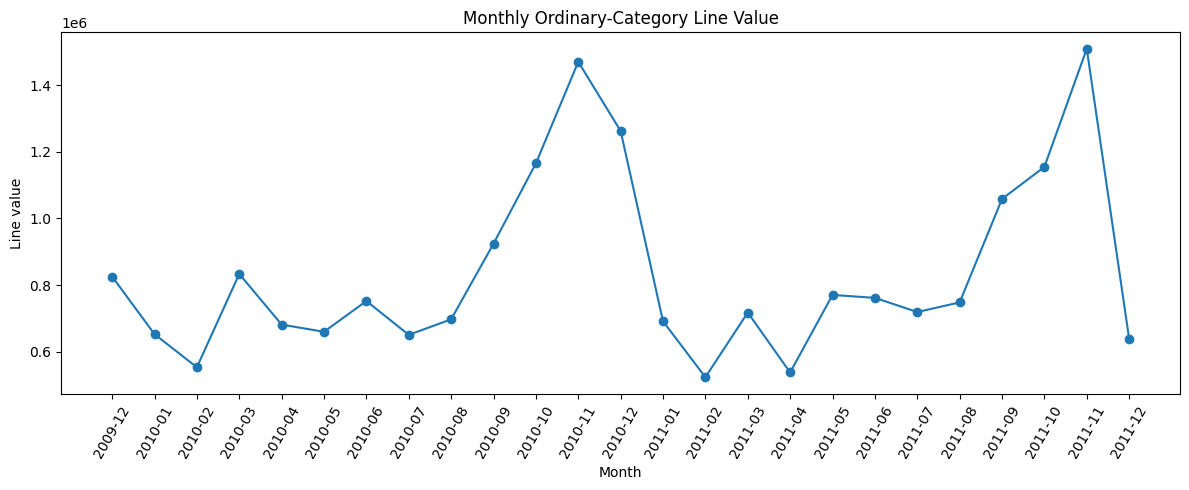

In [3]:
plt.figure(figsize=(12, 5))
plt.plot(
    monthly["year_month"],
    monthly["ordinary_line_value"],
    marker="o"
)
plt.title("Monthly Ordinary-Category Line Value")
plt.xlabel("Month")
plt.ylabel("Line value")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

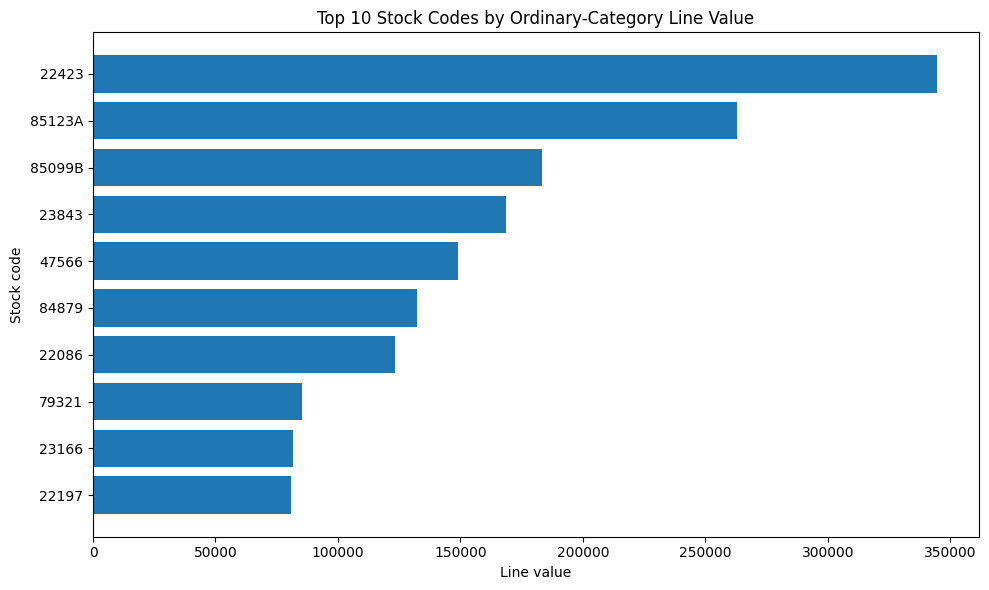

,stock_code,line_value,description,total_units
1655,22423,344563.25,REGENCY CAKESTAND 3 TIER,27594
4363,85123A,263109.67,WHITE HANGING HEART T-LIGHT HOLDER,100152
4335,85099B,183454.83,JUMBO BAG RED WHITE SPOTTY,98356
2817,23843,168469.60,"PAPER CRAFT , LITTLE BIRDIE",80995
3179,47566,149187.05,PARTY BUNTING,28426
4046,84879,132187.92,ASSORTED COLOUR BIRD ORNAMENT,81817
1342,22086,123141.54,PAPER CHAIN KIT 50'S CHRISTMAS,36610
3489,79321,85489.91,CHILLI LIGHTS,16987
2371,23166,81700.92,MEDIUM CERAMIC TOP STORAGE JAR,78033
1449,22197,80920.64,"POPCORN HOLDER , SMALL",90392


In [4]:
product_summary = (
    ordinary[~ordinary["stock_code"].isin(["M", "DOT", "POST"])]
    .groupby("stock_code", as_index=False)
    .agg(
        line_value=("line_value", "sum"),
        description=("description", "first"),
        total_units=("quantity", "sum"),
    )
    .sort_values("line_value", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
plt.barh(product_summary["stock_code"], product_summary["line_value"])
plt.title("Top 10 Stock Codes by Ordinary-Category Line Value")
plt.xlabel("Line value")
plt.ylabel("Stock code")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

product_summary

In [5]:
images_dir = project_dir / "images"
images_dir.mkdir(exist_ok=True)

plt.savefig(
    images_dir / "monthly_line_value.png",
    dpi=150,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [6]:

from pathlib import Path
import matplotlib.pyplot as plt

images_dir = project_dir / "images"
images_dir.mkdir(parents=True, exist_ok=True)

# For the monthly chart, after creating the plot:
plt.savefig(
    images_dir / "monthly_line_value.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()


<Figure size 640x480 with 0 Axes>

In [7]:

overlap_start = pd.Timestamp("2010-12-01")
overlap_end = pd.Timestamp("2010-12-09 23:59:59")

overlap_df = df[
    df["invoice_date"].between(overlap_start, overlap_end)
]

print("Prepared rows in overlap window:", len(overlap_df))
print(
    "Extra duplicate occurrences in window:",
    int(overlap_df["is_duplicate_extra"].sum())
)
print(
    "Rows in duplicate groups in window:",
    int(overlap_df["is_in_duplicate_group"].sum())
)


Prepared rows in overlap window: 45046
Extra duplicate occurrences in window: 22844
Rows in duplicate groups in window: 45046
